In [1]:

%pip install -q "qiskit>=2.1,<3" "qiskit-optimization>=0.7,<0.8" "qiskit-aer>=0.17"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.0/664.0 kB 12.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 85.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 237.1/237.1 kB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 87.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 79.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.3 MB/s eta 0:00:00


In [5]:

# PROCESSOR A: 5 qubits, 5 sites
sites_A = ["A", "B", "C", "D", "E"]
values_A = [9, 7, 6, 5, 4]
weights_A = [6, 5, 4, 3, 2]

# PROCESSOR B: 9 qubits, 9 sites
sites_B = list("ABCDEFGHI")
values_B = [9, 7, 6, 5, 4, 8, 3, 6, 5]
weights_B = [6, 5, 4, 3, 2, 5, 2, 4, 3]

# SAME ENERGY BUDGET FOR BOTH
ENERGY_BUDGET = 10

budget_A = ENERGY_BUDGET
budget_B = ENERGY_BUDGET

print("Processor A:", len(sites_A), "qubits | Budget:", budget_A)
print("Processor B:", len(sites_B), "qubits | Budget:", budget_B)



Processor A: 5 qubits | Budget: 10
Processor B: 9 qubits | Budget: 10


In [6]:

# Same QAOA settings for a fair comparison
COMMON_SETTINGS = {
    "reps": 2,
    "maxiter": 60,
    "shots": 4096,
    "seed": 42
}

result_A = solve_drone_qaoa(
    sites_A, values_A, weights_A, budget_A,
    **COMMON_SETTINGS
)

result_B = solve_drone_qaoa(
    sites_B, values_B, weights_B, budget_B,
    **COMMON_SETTINGS
)

show_result("PROCESSOR A — 5 QUBITS",
            result_A, sites_A, budget_A)

show_result("PROCESSOR B — 9 QUBITS",
            result_B, sites_B, budget_B)



PROCESSOR A — 5 QUBITS
Qubits: 5
QAOA layers (p): 2
Sampled feasible outcomes: 2754 / 4096
QAOA-selected sites: ['B', 'D', 'E']
Total priority: 16
Energy used: 10 / 10
Energy remaining: 0

Exact classical optimum:
Selected sites: ['B', 'D', 'E']
Total priority: 16
Energy used: 10 / 10

QAOA optimization runtime: 1.016 seconds

PROCESSOR B — 9 QUBITS
Qubits: 9
QAOA layers (p): 2
Sampled feasible outcomes: 2084 / 4096
QAOA-selected sites: ['D', 'E', 'F']
Total priority: 17
Energy used: 10 / 10
Energy remaining: 0

Exact classical optimum:
Selected sites: ['D', 'E', 'F']
Total priority: 17
Energy used: 10 / 10

QAOA optimization runtime: 10.669 seconds


In [7]:

for name, result, budget in [
    ("Processor A", result_A, budget_A),
    ("Processor B", result_B, budget_B)
]:
    print(f"\n{name}")

    if result["qaoa"] is None:
        print("No feasible selection found in QAOA samples.")
    else:
        value, energy, selected = result["qaoa"]

        print("Selected sites:",
              [((sites_A if name == "Processor A"
                 else sites_B)[i]) for i in selected])
        print("Priority:", value)
        print("Energy used:", energy)
        print("Energy budget:", budget)
        print("Energy remaining:", budget - energy)

        assert energy <= budget, "Budget constraint violated!"

print("\nBoth processors use the same energy budget:", ENERGY_BUDGET)



Processor A
Selected sites: ['B', 'D', 'E']
Priority: 16
Energy used: 10
Energy budget: 10
Energy remaining: 0

Processor B
Selected sites: ['D', 'E', 'F']
Priority: 17
Energy used: 10
Energy budget: 10
Energy remaining: 0

Both processors use the same energy budget: 10


In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def get_comparison_row(name, result, sites, budget):
    exact_value, exact_energy, exact_selected = result["exact"]

    qaoa = result["qaoa"]

    if qaoa is None:
        qaoa_value = None
        qaoa_energy = None
        qaoa_sites = "No feasible sample"
        gap = None
    else:
        qaoa_value, qaoa_energy, selected = qaoa
        qaoa_sites = ", ".join(sites[i] for i in selected)

        gap = (
            100 * (exact_value - qaoa_value) / exact_value
            if exact_value > 0 else 0
        )

    return {
        "Processor": name,
        "Qubits": result["n"],
        "Energy Budget": budget,
        "QAOA Priority": qaoa_value,
        "QAOA Energy Used": qaoa_energy,
        "QAOA Sites": qaoa_sites,
        "Classical Optimal Priority": exact_value,
        "Optimal Energy Used": exact_energy,
        "Optimal Sites": ", ".join(
            sites[i] for i in exact_selected
        ),
        "Optimality Gap (%)": gap,
        "Runtime (seconds)": round(result["runtime"], 4)
    }

comparison = pd.DataFrame([
    get_comparison_row(
        "Processor A", result_A, sites_A, budget_A
    ),
    get_comparison_row(
        "Processor B", result_B, sites_B, budget_B
    )
])

display(comparison)


,Processor,Qubits,Energy Budget,QAOA Priority,QAOA Energy Used,QAOA Sites,Classical Optimal Priority,Optimal Energy Used,Optimal Sites,Optimality Gap (%),Runtime (seconds)
0,Processor A,5,10,16,10,"B, D, E",16,10,"B, D, E",0.0,1.0163
1,Processor B,9,10,17,10,"D, E, F",17,10,"D, E, F",0.0,10.6686


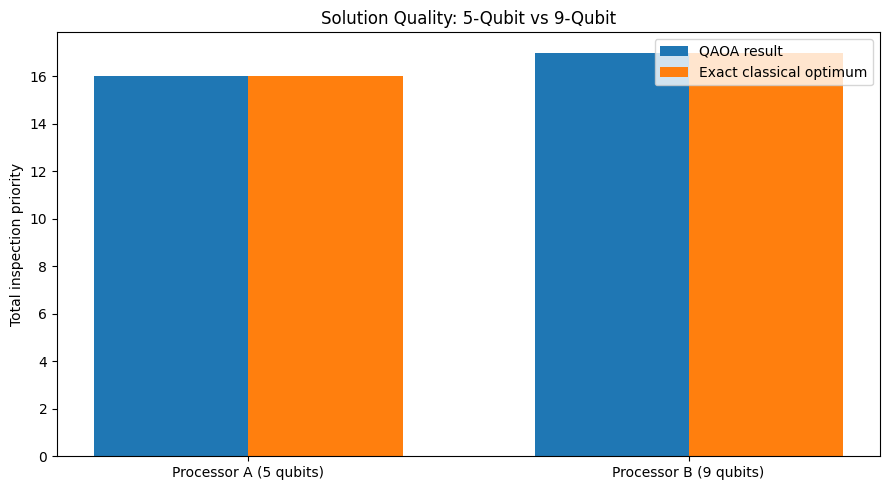

In [9]:

processors = ["Processor A (5 qubits)", "Processor B (9 qubits)"]

qaoa_values = [
    np.nan if result_A["qaoa"] is None else result_A["qaoa"][0],
    np.nan if result_B["qaoa"] is None else result_B["qaoa"][0]
]

classical_values = [
    result_A["exact"][0],
    result_B["exact"][0]
]

x = np.arange(len(processors))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, qaoa_values, width,
        label="QAOA result")
plt.bar(x + width/2, classical_values, width,
        label="Exact classical optimum")

plt.xticks(x, processors)
plt.ylabel("Total inspection priority")
plt.title("Solution Quality: 5-Qubit vs 9-Qubit")
plt.legend()
plt.tight_layout()
plt.show()


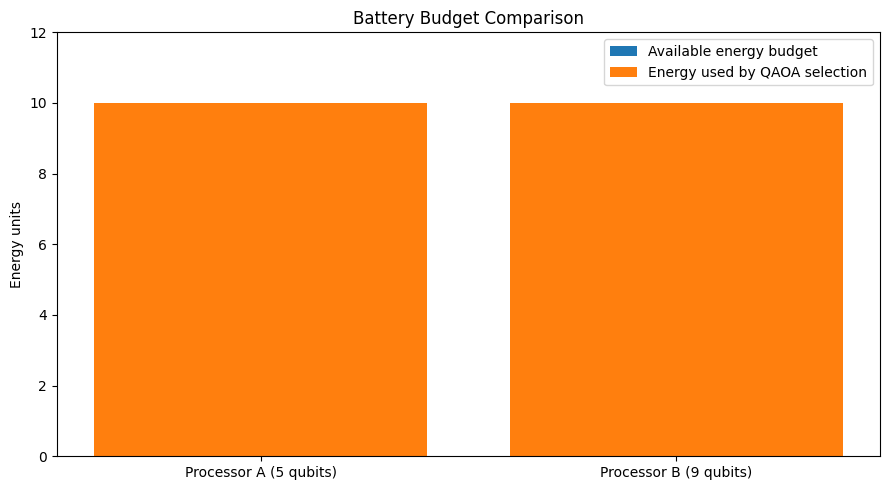

In [10]:

qaoa_energy = [
    np.nan if result_A["qaoa"] is None else result_A["qaoa"][1],
    np.nan if result_B["qaoa"] is None else result_B["qaoa"][1]
]

plt.figure(figsize=(9, 5))

plt.bar(processors, [ENERGY_BUDGET, ENERGY_BUDGET],
        label="Available energy budget")

plt.bar(processors, [
    0 if np.isnan(e) else e for e in qaoa_energy
], label="Energy used by QAOA selection")

plt.ylabel("Energy units")
plt.title("Battery Budget Comparison")
plt.ylim(0, ENERGY_BUDGET + 2)
plt.legend()
plt.tight_layout()
plt.show()


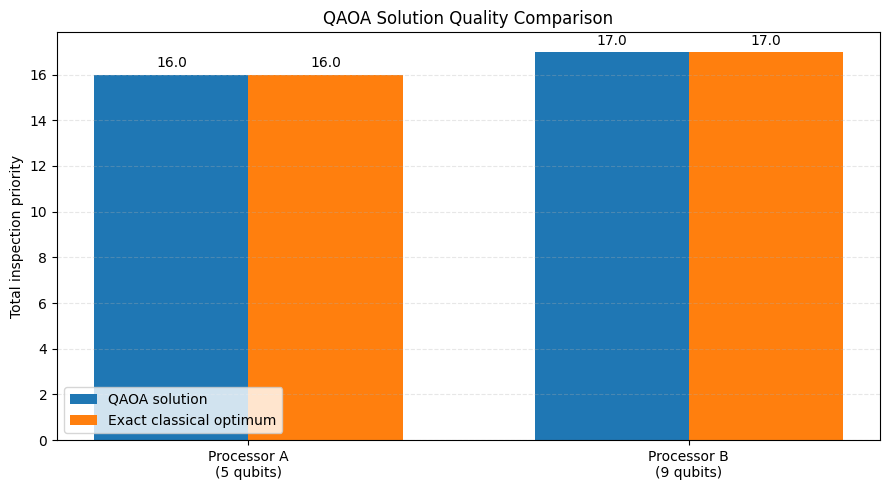

In [12]:

import matplotlib.pyplot as plt
import numpy as np

# Get the best QAOA priority and exact classical optimum
names = ["Processor A\n(5 qubits)", "Processor B\n(9 qubits)"]

qaoa_scores = [
    result_A["qaoa"][0] if result_A["qaoa"] is not None else np.nan,
    result_B["qaoa"][0] if result_B["qaoa"] is not None else np.nan
]

classical_scores = [
    result_A["exact"][0],
    result_B["exact"][0]
]

x = np.arange(len(names))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(
    x - width/2, qaoa_scores, width,
    label="QAOA solution"
)

bars2 = ax.bar(
    x + width/2, classical_scores, width,
    label="Exact classical optimum"
)

ax.set_title("QAOA Solution Quality Comparison")
ax.set_ylabel("Total inspection priority")
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

ax.bar_label(bars1, padding=3, fmt="%.1f")
ax.bar_label(bars2, padding=3, fmt="%.1f")

plt.tight_layout()
plt.show()


In [13]:

import pandas as pd

def compare_processor(name, result, sites, budget):
    exact_value, exact_energy, exact_selected = result["exact"]
    qaoa = result["qaoa"]

    if qaoa is not None:
        q_value, q_energy, q_selected = qaoa
        gap = 100 * (exact_value - q_value) / exact_value if exact_value else 0
        selected_sites = ", ".join(sites[i] for i in q_selected)
    else:
        q_value, q_energy, gap = None, None, None
        selected_sites = "No feasible sample"

    return {
        "Processor": name,
        "Qubits": result["n"],
        "Energy budget": budget,
        "QAOA selected sites": selected_sites,
        "QAOA priority": q_value,
        "QAOA energy used": q_energy,
        "Classical optimal priority": exact_value,
        "Optimality gap (%)": round(gap, 2) if gap is not None else None,
        "Runtime (s)": round(result["runtime"], 4)
    }

comparison = pd.DataFrame([
    compare_processor("Processor A", result_A, sites_A, 10),
    compare_processor("Processor B", result_B, sites_B, 10)
])

display(comparison)


,Processor,Qubits,Energy budget,QAOA selected sites,QAOA priority,QAOA energy used,Classical optimal priority,Optimality gap (%),Runtime (s)
0,Processor A,5,10,"B, D, E",16,10,16,0.0,1.0163
1,Processor B,9,10,"D, E, F",17,10,17,0.0,10.6686


In [15]:
!pip install qiskit matplotlib pylatexenc


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 3.6 MB/s eta 0:00:00


In [17]:

%pip install pylatexenc


In [20]:

import sys
import qiskit
import pylatexenc

print("Python:", sys.executable)
print("Qiskit:", qiskit.__version__)
print("pylatexenc:", pylatexenc.__file__)


Python: /usr/bin/python3
Qiskit: 2.6.0
pylatexenc: /usr/local/lib/python3.13/dist-packages/pylatexenc/__init__.py


In [22]:

from IPython.display import display, HTML

print("PROCESSOR A — 5 QUBITS")
display(HTML(
    "<h3>Processor A: QAOA Circuit</h3><pre>" +
    str(circuit_A.draw(output="text", fold=100)) +
    "</pre>"
))

print("PROCESSOR B — 9 QUBITS")
display(HTML(
    "<h3>Processor B: QAOA Circuit</h3><pre>" +
    str(circuit_B.draw(output="text", fold=100)) +
    "</pre>"
))


PROCESSOR A — 5 QUBITS


PROCESSOR B — 9 QUBITS


In [23]:

import itertools
import time
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Problem configurations
# -----------------------------
sites_A = ["A", "B", "C", "D", "E"]
values_A = [9, 7, 6, 5, 4]
weights_A = [6, 5, 4, 3, 2]

sites_B = list("ABCDEFGHI")
values_B = [9, 7, 6, 5, 4, 8, 3, 6, 5]
weights_B = [6, 5, 4, 3, 2, 5, 2, 4, 3]

BUDGET = 10


# -----------------------------
# Classical exhaustive search
# -----------------------------
def exhaustive_search(sites, values, weights, budget):
    start = time.perf_counter()

    n = len(sites)
    best_value = -1
    best_energy = 0
    best_selection = []

    # Enumerate every possible binary selection
    for bits in itertools.product([0, 1], repeat=n):
        energy = sum(
            weights[i] * bits[i] for i in range(n)
        )
        priority = sum(
            values[i] * bits[i] for i in range(n)
        )

        # Accept only feasible selections
        if energy <= budget and priority > best_value:
            best_value = priority
            best_energy = energy
            best_selection = [
                sites[i] for i in range(n) if bits[i] == 1
            ]

    elapsed = time.perf_counter() - start

    return {
        "Qubits": n,
        "Combinations checked": 2 ** n,
        "Selected sites": ", ".join(best_selection),
        "Priority": best_value,
        "Energy used": best_energy,
        "Runtime (seconds)": elapsed
    }


# Run exhaustive search for both configurations
result_A = exhaustive_search(
    sites_A, values_A, weights_A, BUDGET
)

result_B = exhaustive_search(
    sites_B, values_B, weights_B, BUDGET
)

classical_results = pd.DataFrame([
    {"Processor": "A", **result_A},
    {"Processor": "B", **result_B}
])

print("CLASSICAL EXHAUSTIVE SEARCH RESULTS")
display(classical_results.round(6))


CLASSICAL EXHAUSTIVE SEARCH RESULTS


,Processor,Qubits,Combinations checked,Selected sites,Priority,Energy used,Runtime (seconds)
0,A,5,32,"B, D, E",16,10,0.000121
1,B,9,512,"E, F, I",17,10,0.004033


In [24]:

# Previously reported QAOA-inspired results
qaoa_results = {
    "A": {"Priority": 16, "Energy": 10,
          "Runtime": 1.0163},
    "B": {"Priority": 17, "Energy": 10,
          "Runtime": 10.6686}
}

comparison = []

for result in [result_A, result_B]:
    processor = "A" if result is result_A else "B"

    classical_priority = result["Priority"]
    qaoa_priority = qaoa_results[processor]["Priority"]

    gap = (
        (classical_priority - qaoa_priority)
        / classical_priority * 100
        if classical_priority != 0 else 0
    )

    comparison.append({
        "Processor": processor,
        "Qubits": result["Qubits"],
        "Combinations": result["Combinations checked"],
        "Classical priority": classical_priority,
        "QAOA priority": qaoa_priority,
        "Classical energy": result["Energy used"],
        "QAOA energy": qaoa_results[processor]["Energy"],
        "Optimality gap (%)": gap,
        "Classical runtime (s)": result["Runtime (seconds)"],
        "QAOA runtime (s)": qaoa_results[processor]["Runtime"]
    })

comparison_df = pd.DataFrame(comparison)

print("QAOA-INSPIRED VS CLASSICAL EXHAUSTIVE SEARCH")
display(comparison_df.round(4))


QAOA-INSPIRED VS CLASSICAL EXHAUSTIVE SEARCH


,Processor,Qubits,Combinations,Classical priority,QAOA priority,Classical energy,QAOA energy,Optimality gap (%),Classical runtime (s),QAOA runtime (s)
0,A,5,32,16,16,10,10,0.0,0.0001,1.0163
1,B,9,512,17,17,10,10,0.0,0.0040,10.6686


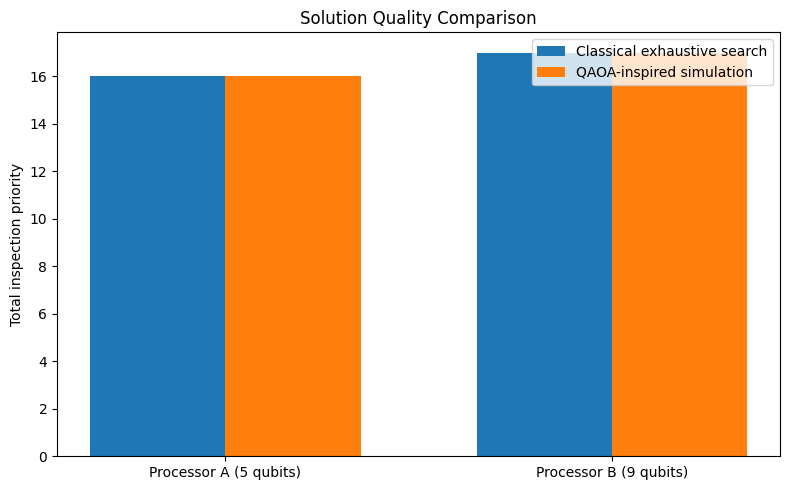

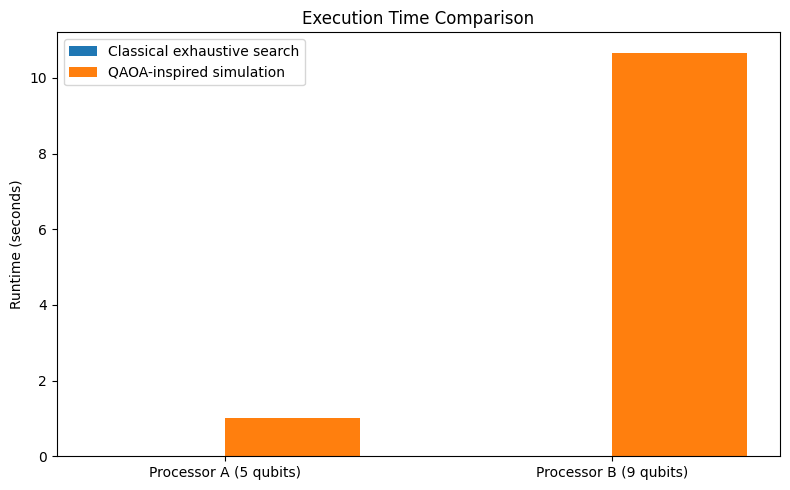

In [25]:

# Compare solution priority
x = [0, 1]
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

classical_values = comparison_df["Classical priority"].tolist()
qaoa_values = comparison_df["QAOA priority"].tolist()

ax.bar(
    [i - width/2 for i in x],
    classical_values,
    width,
    label="Classical exhaustive search"
)
ax.bar(
    [i + width/2 for i in x],
    qaoa_values,
    width,
    label="QAOA-inspired simulation"
)

ax.set_xticks(x)
ax.set_xticklabels(["Processor A (5 qubits)",
                    "Processor B (9 qubits)"])
ax.set_ylabel("Total inspection priority")
ax.set_title("Solution Quality Comparison")
ax.legend()
plt.tight_layout()
plt.show()


# Compare measured runtimes
fig, ax = plt.subplots(figsize=(8, 5))

classical_time = comparison_df["Classical runtime (s)"].tolist()
qaoa_time = comparison_df["QAOA runtime (s)"].tolist()

ax.bar(
    [i - width/2 for i in x],
    classical_time,
    width,
    label="Classical exhaustive search"
)
ax.bar(
    [i + width/2 for i in x],
    qaoa_time,
    width,
    label="QAOA-inspired simulation"
)

ax.set_xticks(x)
ax.set_xticklabels(["Processor A (5 qubits)",
                    "Processor B (9 qubits)"])
ax.set_ylabel("Runtime (seconds)")
ax.set_title("Execution Time Comparison")
ax.legend()
plt.tight_layout()
plt.show()
